# MLP from scratch (two hidden layers)
first we shall use sigmoid function

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split


In [2]:
import pandas as pd
df_encoded = pd.read_csv("../data/df_encoded.csv")
print(df_encoded.head())



   minimum_nights  amenity_score  number_of_reviews  availability_365  \
0       -0.251024       1.586358          -0.184981          1.095654   
1       -0.251024       0.089685          -0.503065         -0.849587   
2       -0.251024      -0.216925           1.064634         -0.160329   
3       -0.251024       0.354721          -0.503065         -0.512616   
4       -0.251024      -1.027623          -0.525785         -0.167987   

   price_class  neighbourhood_group_Bronx  neighbourhood_group_Brooklyn  \
0            3                      False                         False   
1            1                      False                         False   
2            1                      False                          True   
3            1                      False                         False   
4            1                       True                         False   

   neighbourhood_group_Manhattan  neighbourhood_group_Queens  \
0                           True              

### Step 1 : Prepare data 

In [3]:
import numpy as np
X = df_encoded.drop("price_class", axis=1).to_numpy(dtype=np.float64)
y = df_encoded["price_class"].values

Y = np.zeros((y.size, y.max()+1))
Y[np.arange(y.size), y] = 1

X_train, X_val, Y_train, Y_val = train_test_split(X, Y, test_size=0.2, random_state=42)

print("Training samples:", X_train.shape[0])
print("Validation samples:", X_val.shape[0])
print("X_train dtype:", X_train.dtype) 


Training samples: 33078
Validation samples: 8270
X_train dtype: float64


### Step 2 : Now I will initialize Network Parameters

In [4]:
input_size = X_train.shape[1]
hidden1_size = 32
hidden2_size = 16
output_size = Y_train.shape[1]

W1 = np.random.randn(input_size, hidden1_size) * 0.01
b1 = np.zeros((1, hidden1_size))

W2 = np.random.randn(hidden1_size, hidden2_size) * 0.01
b2 = np.zeros((1, hidden2_size))

W3 = np.random.randn(hidden2_size, output_size) * 0.01
b3 = np.zeros((1, output_size))


### Step 3: Now sigmoid func. its derivate and softmax for o/p layer

In [5]:
# Sigmoid
def sigmoid(Z):
    return 1 / (1 + np.exp(-Z))

def sigmoid_derivative(A):
    return A * (1 - A)

# Softmax
def softmax(Z):
    expZ = np.exp(Z - np.max(Z, axis=1, keepdims=True))
    return expZ / np.sum(expZ, axis=1, keepdims=True)


### Step 4: Forward Propagation

In [6]:
def forward_propagation(X, W1, b1, W2, b2, W3, b3):
    Z1 = X @ W1 + b1
    A1 = sigmoid(Z1)
    
    Z2 = A1 @ W2 + b2
    A2 = sigmoid(Z2)
    
    Z3 = A2 @ W3 + b3
    Y_hat = softmax(Z3)
    
    cache = (Z1, A1, Z2, A2, Z3, Y_hat)
    return Y_hat, cache


###Step 5: Compute Cross-Entropy Loss

In [7]:
def compute_loss(Y_hat, Y):
    m = Y.shape[0]
    loss = -np.sum(Y * np.log(Y_hat + 1e-8)) / m
    return loss


###  Step 6: Backward Propagation

In [8]:
def backward_propagation(X, Y, cache, W2, W3):
    Z1, A1, Z2, A2, Z3, Y_hat = cache
    m = Y.shape[0]
    
    # Output layer
    dZ3 = (Y_hat - Y) / m
    dW3 = A2.T @ dZ3
    db3 = np.sum(dZ3, axis=0, keepdims=True)
    
    # Hidden layer 2
    dA2 = dZ3 @ W3.T
    dZ2 = dA2 * sigmoid_derivative(A2)
    dW2 = A1.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)
    
    # Hidden layer 1
    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * sigmoid_derivative(A1)
    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)
    
    return dW1, db1, dW2, db2, dW3, db3


### Step 7: Accuracy Function

In [9]:
def compute_accuracy(Y_hat, Y):
    y_pred = np.argmax(Y_hat, axis=1)
    y_true = np.argmax(Y, axis=1)
    accuracy = np.mean(y_pred == y_true)
    return accuracy


In [10]:
grad_W1_history_sigmoid = []
grad_W2_history_sigmoid = []


### Step 8: Training Loop

In [11]:
learning_rate = 0.1
num_iterations = 200

train_acc_history = []
val_acc_history = []

for i in range(num_iterations):
    # Forward pass
    Y_hat_train, cache = forward_propagation(X_train, W1, b1, W2, b2, W3, b3)
    loss = compute_loss(Y_hat_train, Y_train)
    
    # Backward pass
    dW1, db1, dW2, db2, dW3, db3 = backward_propagation(X_train, Y_train, cache, W2, W3)
    
    # Update weights
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2
    W3 -= learning_rate * dW3
    b3 -= learning_rate * db3
    
    # Here i am finding average gradient magnitude
    grad_W1_history_sigmoid.append(np.mean(np.abs(dW1)))
    grad_W2_history_sigmoid.append(np.mean(np.abs(dW2)))

    
    # Compute accuracies
    Y_hat_val, _ = forward_propagation(X_val, W1, b1, W2, b2, W3, b3)
    train_acc = compute_accuracy(Y_hat_train, Y_train)
    val_acc = compute_accuracy(Y_hat_val, Y_val)
    
    train_acc_history.append(train_acc)
    val_acc_history.append(val_acc)
    
    if i % 20 == 0:
        print(f"Iteration {i}: Loss = {loss:.4f}, Train Acc = {train_acc:.4f}, Val Acc = {val_acc:.4f}")


Iteration 0: Loss = 1.3849, Train Acc = 0.1335, Val Acc = 0.5583
Iteration 20: Loss = 1.1144, Train Acc = 0.5644, Val Acc = 0.5583
Iteration 40: Loss = 1.1101, Train Acc = 0.5644, Val Acc = 0.5583
Iteration 60: Loss = 1.1096, Train Acc = 0.5644, Val Acc = 0.5583
Iteration 80: Loss = 1.1095, Train Acc = 0.5644, Val Acc = 0.5583
Iteration 100: Loss = 1.1095, Train Acc = 0.5644, Val Acc = 0.5583
Iteration 120: Loss = 1.1095, Train Acc = 0.5644, Val Acc = 0.5583
Iteration 140: Loss = 1.1095, Train Acc = 0.5644, Val Acc = 0.5583
Iteration 160: Loss = 1.1095, Train Acc = 0.5644, Val Acc = 0.5583
Iteration 180: Loss = 1.1095, Train Acc = 0.5644, Val Acc = 0.5583


In [12]:
# After Sigmoid training loop
train_acc_history_sigmoid = train_acc_history.copy()
val_acc_history_sigmoid = val_acc_history.copy()

### Step 9: Plot Training & Validation Accuracy

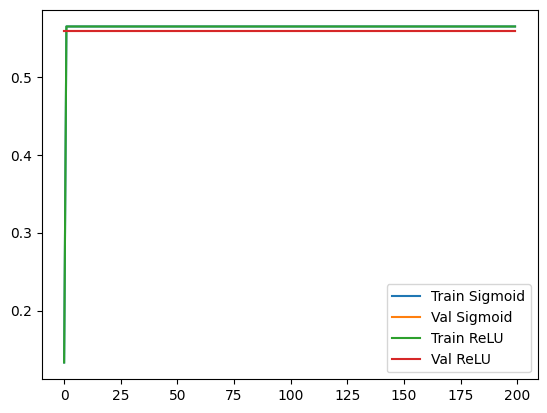

In [13]:
plt.plot(train_acc_history_sigmoid, label="Train Sigmoid")
plt.plot(val_acc_history_sigmoid, label="Val Sigmoid")
plt.plot(train_acc_history, label="Train ReLU")  # ReLU history
plt.plot(val_acc_history, label="Val ReLU")      # ReLU history
plt.legend()
plt.show()


# ReLU Activation function

In [25]:

def relu(Z):
    return np.maximum(0, Z)

def relu_derivative(Z):
    return (Z > 0).astype(float)


In [27]:
def forward_propagationR(X, W1, b1, W2, b2, W3, b3):
    Z1 = X @ W1 + b1
    A1 = relu(Z1)   

    Z2 = A1 @ W2 + b2
    A2 = relu(Z2)   

    Z3 = A2 @ W3 + b3
    Y_hat = softmax(Z3)

    cache = (Z1, A1, Z2, A2, Z3, Y_hat)
    return Y_hat, cache


In [28]:
def backward_propagationR(X, Y, cache, W2, W3):
    Z1, A1, Z2, A2, Z3, Y_hat = cache
    m = Y.shape[0]

    dZ3 = (Y_hat - Y) / m
    dW3 = A2.T @ dZ3
    db3 = np.sum(dZ3, axis=0, keepdims=True)

    # Hidden layer 2
    dA2 = dZ3 @ W3.T
    dZ2 = dA2 * relu_derivative(Z2)  
    dW2 = A1.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    # Hidden layer 1
    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * relu_derivative(Z1)  
    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    return dW1, db1, dW2, db2, dW3, db3


In [29]:
W1 = np.random.randn(input_size, hidden1_size) * np.sqrt(2 / input_size)
b1 = np.zeros((1, hidden1_size))

W2 = np.random.randn(hidden1_size, hidden2_size) * np.sqrt(2 / hidden1_size)
b2 = np.zeros((1, hidden2_size))

W3 = np.random.randn(hidden2_size, output_size) * 0.01
b3 = np.zeros((1, output_size))


In [30]:
grad_W1_history_relu = []
grad_W2_history_relu = []


In [31]:
learning_rate = 0.1
num_iterations = 200

train_acc_history = []
val_acc_history = []

for i in range(num_iterations):
    # Forward pass
    Y_hat_train, cache = forward_propagationR(X_train, W1, b1, W2, b2, W3, b3)
    loss = compute_loss(Y_hat_train, Y_train)
    
    # Backward pass
    dW1, db1, dW2, db2, dW3, db3 = backward_propagationR(X_train, Y_train, cache, W2, W3)
    
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2
    W3 -= learning_rate * dW3
    b3 -= learning_rate * db3
    
    grad_W1_history_relu.append(np.mean(np.abs(dW1)))
    grad_W2_history_relu.append(np.mean(np.abs(dW2)))

    Y_hat_val, _ = forward_propagationR(X_val, W1, b1, W2, b2, W3, b3)
    train_acc = compute_accuracy(Y_hat_train, Y_train)
    val_acc = compute_accuracy(Y_hat_val, Y_val)
    
    train_acc_history.append(train_acc)
    val_acc_history.append(val_acc)
    
    if i % 20 == 0:
        print(f"Iteration {i}: Loss = {loss:.4f}, Train Acc = {train_acc:.4f}, Val Acc = {val_acc:.4f}")


Iteration 0: Loss = 1.3855, Train Acc = 0.1750, Val Acc = 0.5884
Iteration 20: Loss = 1.0063, Train Acc = 0.6528, Val Acc = 0.6481
Iteration 40: Loss = 0.8057, Train Acc = 0.7024, Val Acc = 0.6947
Iteration 60: Loss = 0.6740, Train Acc = 0.7092, Val Acc = 0.7015
Iteration 80: Loss = 0.5914, Train Acc = 0.7563, Val Acc = 0.7492
Iteration 100: Loss = 0.5366, Train Acc = 0.7805, Val Acc = 0.7709
Iteration 120: Loss = 0.4982, Train Acc = 0.7968, Val Acc = 0.7845
Iteration 140: Loss = 0.4704, Train Acc = 0.8048, Val Acc = 0.7921
Iteration 160: Loss = 0.4495, Train Acc = 0.8104, Val Acc = 0.7970
Iteration 180: Loss = 0.4336, Train Acc = 0.8146, Val Acc = 0.8037


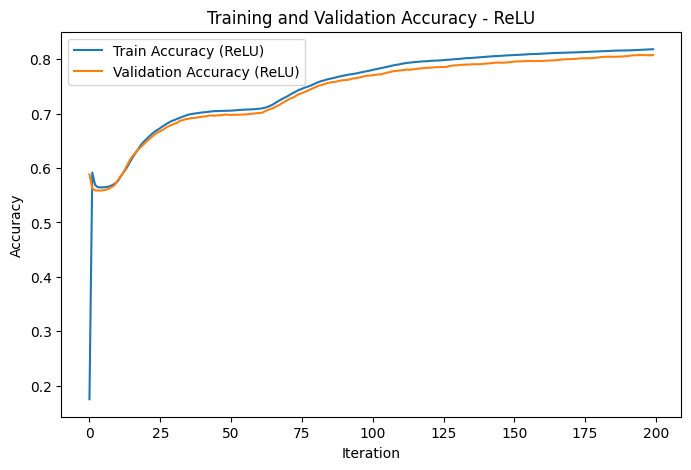

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(train_acc_history, label="Train Accuracy (ReLU)")
plt.plot(val_acc_history, label="Validation Accuracy (ReLU)")
plt.title("Training and Validation Accuracy - ReLU")
plt.xlabel("Iteration")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


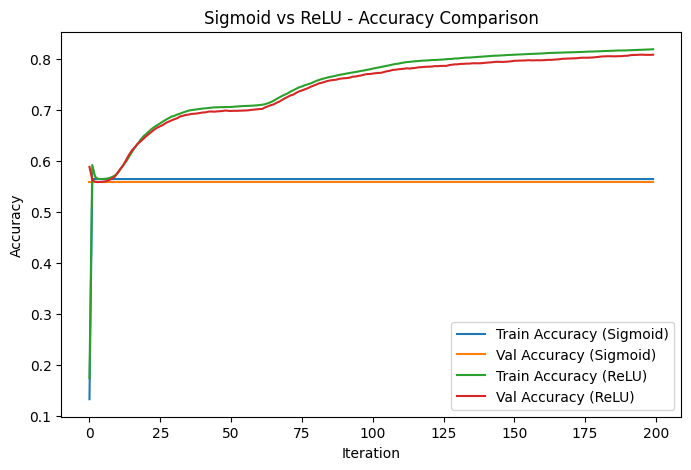

In [33]:
# single plot for sigmoid vs relu
plt.figure(figsize=(8,5))
plt.plot(train_acc_history_sigmoid, label="Train Accuracy (Sigmoid)")
plt.plot(val_acc_history_sigmoid, label="Val Accuracy (Sigmoid)")
plt.plot(train_acc_history, label="Train Accuracy (ReLU)")
plt.plot(val_acc_history, label="Val Accuracy (ReLU)")
plt.title("Sigmoid vs ReLU - Accuracy Comparison")
plt.xlabel("Iteration")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


# Sigmoid vs ReLU
### Comparing gradient magnitudes

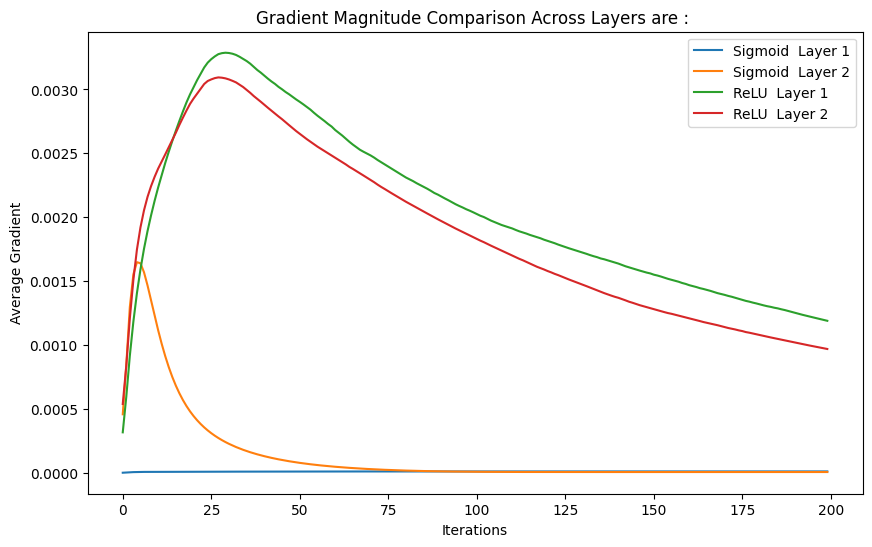

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

# Sigmoid gradients
plt.plot(grad_W1_history_sigmoid, label="Sigmoid  Layer 1")
plt.plot(grad_W2_history_sigmoid, label="Sigmoid  Layer 2")

# ReLU gradients
plt.plot(grad_W1_history_relu, label="ReLU  Layer 1")
plt.plot(grad_W2_history_relu, label="ReLU  Layer 2")

plt.title("Gradient Magnitude Comparison Across Layers are : ")
plt.xlabel("Iterations")
plt.ylabel("Average Gradient")
plt.legend()
plt.show()


In [35]:
print("Iteration | Sigmoid L1 | Sigmoid L2 | ReLU L1 | ReLU L2")

for i in range(0, len(grad_W1_history_sigmoid), 20):
    print(f"{i:9d} | "
          f"{grad_W1_history_sigmoid[i]:.6f} | "
          f"{grad_W2_history_sigmoid[i]:.6f} | "
          f"{grad_W1_history_relu[i]:.6f} | "
          f"{grad_W2_history_relu[i]:.6f}")


Iteration | Sigmoid L1 | Sigmoid L2 | ReLU L1 | ReLU L2
--------------------------------------------------------
        0 | 0.000002 | 0.000459 | 0.000318 | 0.000540
       20 | 0.000010 | 0.000446 | 0.003018 | 0.002929
       40 | 0.000011 | 0.000132 | 0.003108 | 0.002880
       60 | 0.000012 | 0.000049 | 0.002683 | 0.002464
       80 | 0.000012 | 0.000019 | 0.002311 | 0.002121
      100 | 0.000013 | 0.000010 | 0.002025 | 0.001830
      120 | 0.000013 | 0.000008 | 0.001816 | 0.001580
      140 | 0.000013 | 0.000008 | 0.001638 | 0.001370
      160 | 0.000013 | 0.000008 | 0.001469 | 0.001210
      180 | 0.000013 | 0.000008 | 0.001318 | 0.001079


Results reveal that Sigmoid restricts gradient flow in deeper networks, leading to slow or stalled learning. ReLU allows stronger and more stable gradient propagation, enabling more effective weight updates and improved learning.

# Gradient-Based Feature Attribution (Analytical Implementation)


In [38]:
grad_X = np.zeros_like(X_train)  # shape: (num_samples, num_features)


In [ ]:
#full loop for ReLU network
for i in range(X_train.shape[0]):
    x_sample = X_train[i:i+1, :]
    y_sample = Y_train[i:i+1, :]

    # Forward pass
    Y_hat, cache = forward_propagationR(x_sample, W1, b1, W2, b2, W3, b3)

    Z1, A1, Z2, A2, Z3, Y_hat = cache
    delta3 = Y_hat - y_sample
    delta2 = delta3 @ W3.T * relu_derivative(Z2)
    delta1 = delta2 @ W2.T * relu_derivative(Z1)

    # Gradient wrt input
    grad_X[i, :] = delta1 @ W1.T

In [40]:
# Computing abs values of gradients and average on all samples
avg_grad_magnitude = np.mean(np.abs(grad_X), axis=0)

import pandas as pd
feature_names = df_encoded.drop("price_class", axis=1).columns
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "AvgGradientMagnitude": avg_grad_magnitude
})

# Sort features by importance
feature_importance = feature_importance.sort_values(by="AvgGradientMagnitude", ascending=False)
feature_importance.reset_index(drop=True, inplace=True)

feature_importance


,Feature,AvgGradientMagnitude
0,amenity_score,0.862572
1,availability_365,0.206094
2,neighbourhood_group_Queens,0.205375
3,minimum_nights,0.189833
4,neighbourhood_group_Manhattan,0.185769
5,neighbourhood_group_Staten Island,0.183951
6,room_type_Entire home/apt,0.176312
7,neighbourhood_group_Brooklyn,0.162189
8,room_type_Shared room,0.158359
9,room_type_Private room,0.153683


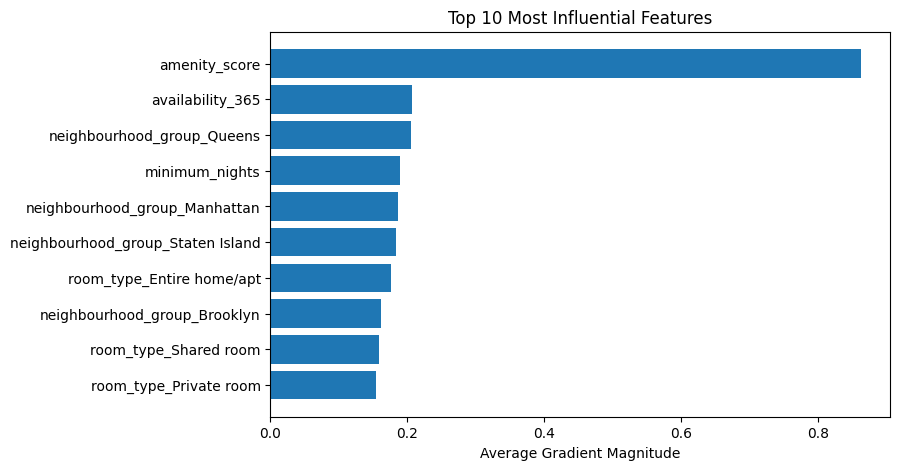

In [41]:
import matplotlib.pyplot as plt

top_n = 10  # show top 10 features
plt.figure(figsize=(8,5))
plt.barh(feature_importance["Feature"][:top_n][::-1], 
         feature_importance["AvgGradientMagnitude"][:top_n][::-1])
plt.xlabel("Average Gradient Magnitude")
plt.title("Top 10 Most Influential Features")
plt.show()


# Test Evaluation and Generalization Analysis

In [46]:
import pandas as pd
import numpy as np

# Load test dataset
df_test = pd.read_csv("../data/test.csv")
df_test.head()


,neighbourhood_group,room_type,minimum_nights,amenity_score,number_of_reviews,availability_365,price_class
0,Brooklyn,Entire home/apt,2,84.3,127,270,2
1,Brooklyn,Private room,7,79.5,0,176,1
2,Manhattan,Private room,3,97.1,17,65,2
3,Manhattan,Private room,3,77.4,2,0,1
4,Manhattan,Entire home/apt,2,28.7,27,180,2


In [47]:
df_test.isnull().sum()

neighbourhood_group    0
room_type              0
minimum_nights         0
amenity_score          0
number_of_reviews      0
availability_365       0
price_class            0
dtype: int64

In [48]:
from sklearn.preprocessing import StandardScaler

In [ ]:
# to get the same scaler used in training
import joblib
scaler = joblib.load("../data/scaler.pkl")


In [ ]:

categorical_cols = ["neighbourhood_group", "room_type"]
df_test_encoded = pd.get_dummies(df_test, columns=categorical_cols, drop_first=False)

for col in df_encoded.columns:
    if col not in df_test_encoded.columns:
        df_test_encoded[col] = 0

df_test_encoded = df_test_encoded[df_encoded.drop("price_class", axis=1).columns]

numeric_cols = ["minimum_nights", "amenity_score", "number_of_reviews", "availability_365"]
df_test_encoded[numeric_cols] = scaler.transform(df_test_encoded[numeric_cols])


In [54]:
X_test = df_test_encoded.to_numpy(dtype=np.float64)

Y_test = df_test["price_class"].values

# One-hot encoding
Y_test_onehot = np.zeros((Y_test.size, Y_test.max()+1))
Y_test_onehot[np.arange(Y_test.size), Y_test] = 1


In [ ]:
# Forward pass on the test set : RELU activation
Y_hat_test, _ = forward_propagationR(X_test, W1, b1, W2, b2, W3, b3)

test_acc = compute_accuracy(Y_hat_test, Y_test_onehot)
print("Test Accuracy:", test_acc)


Test Accuracy: 0.12909414828011512


In [ ]:
final_train_acc = train_acc_history[-1]
final_val_acc = val_acc_history[-1]

print("Final Training Accuracy:", final_train_acc)
print("Final Validation Accuracy:", final_val_acc)
print("Test Accuracy:", test_acc)  # from Step 1


Final Training Accuracy: 0.8185500937178789
Final Validation Accuracy: 0.8078597339782346
Test Accuracy: 0.12909414828011512


In [60]:
import pandas as pd

accuracy_df = pd.DataFrame({
    "Set": ["Training", "Validation", "Test"],
    "Accuracy": [final_train_acc, final_val_acc, test_acc]
})

print(accuracy_df)


          Set  Accuracy
0    Training  0.818550
1  Validation  0.807860
2        Test  0.129094


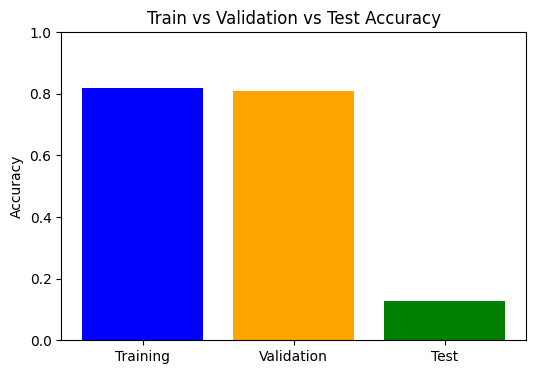

In [61]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
plt.bar(accuracy_df["Set"], accuracy_df["Accuracy"], color=["blue","orange","green"])
plt.ylim(0,1)
plt.ylabel("Accuracy")
plt.title("Train vs Validation vs Test Accuracy")
plt.show()


### observation
The final training accuracy (82%) and validation accuracy (81%) are high, indicating the network successfully learned patterns in the training set. However, the test accuracy drops drastically to 13%, which clearly shows the model fails to generalize to unseen data. This gap suggests overfitting and heavy reliance on features specific to the training set, such as 'amenity_score

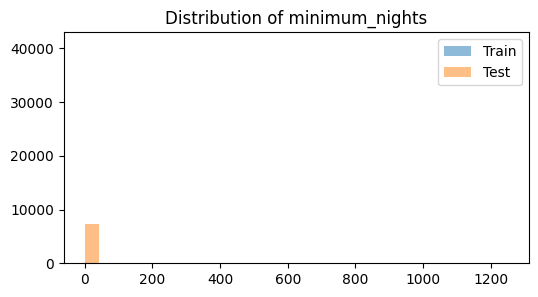

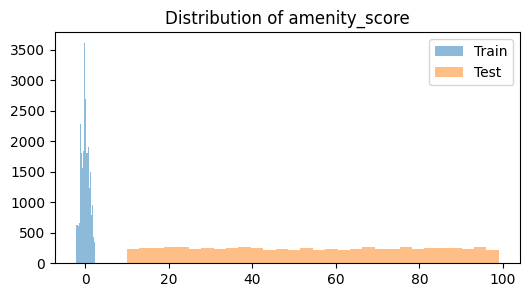

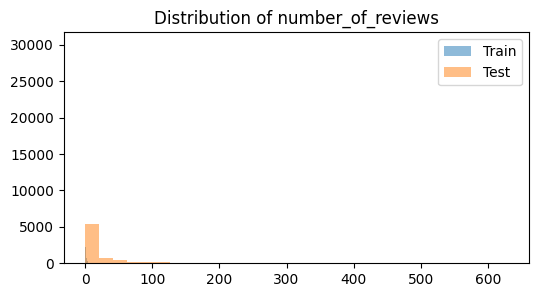

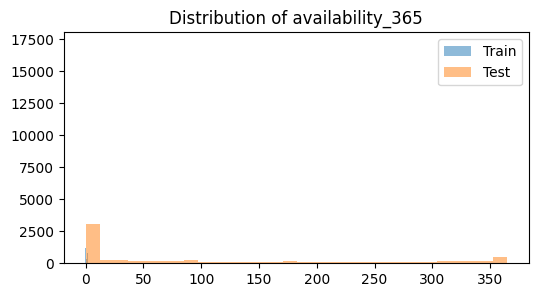

In [ ]:
# lets understand ROOT CAUSE OF GEENRALIZATION FAILURE

import matplotlib.pyplot as plt
numeric_cols = ["minimum_nights", "amenity_score", "number_of_reviews", "availability_365"]

for col in numeric_cols:
    plt.figure(figsize=(6,3))
    plt.hist(df_encoded[col], bins=30, alpha=0.5, label="Train")
    plt.hist(df_test_encoded[col], bins=30, alpha=0.5, label="Test")
    plt.title(f"Distribution of {col}")
    plt.legend()
    plt.show()


In [ ]:
import numpy as np

numeric_cols = ["minimum_nights", "amenity_score", "number_of_reviews", "availability_365"]
bins = 30 

for col in numeric_cols:
   
    train_counts, train_edges = np.histogram(df_encoded[col], bins=bins)
    test_counts, test_edges = np.histogram(df_test_encoded[col], bins=train_edges)  
    
    print(f"\nDistribution for {col}:")
    print("Bin range\tTrain Count\tTest Count")
    for i in range(len(train_counts)):
        print(f"{train_edges[i]:.2f} - {train_edges[i+1]:.2f}\t{train_counts[i]}\t{test_counts[i]}")



Distribution for minimum_nights:
Bin range	Train Count	Test Count
-0.30 - 1.41	40918	1904
1.41 - 3.13	171	2937
3.13 - 4.84	122	489
4.84 - 6.56	34	621
6.56 - 8.27	8	285
8.27 - 9.99	43	12
9.99 - 11.70	4	77
11.70 - 13.42	4	24
13.42 - 15.13	8	135
15.13 - 16.84	0	1
16.84 - 18.56	27	6
18.56 - 20.27	0	25
20.27 - 21.99	0	15
21.99 - 23.70	0	2
23.70 - 25.42	5	17
25.42 - 27.13	0	5
27.13 - 28.85	0	26
28.85 - 30.56	0	614
30.56 - 32.28	0	29
32.28 - 33.99	0	0
33.99 - 35.71	0	2
35.71 - 37.42	0	0
37.42 - 39.14	0	0
39.14 - 40.85	0	0
40.85 - 42.57	0	0
42.57 - 44.28	0	0
44.28 - 46.00	0	7
46.00 - 47.71	0	0
47.71 - 49.42	0	0
49.42 - 51.14	4	0

Distribution for amenity_score:
Bin range	Train Count	Test Count
-2.18 - -2.03	628	0
-2.03 - -1.87	610	0
-1.87 - -1.72	625	0
-1.72 - -1.56	607	0
-1.56 - -1.41	691	0
-1.41 - -1.26	667	0
-1.26 - -1.10	2141	0
-1.10 - -0.95	2275	0
-0.95 - -0.79	1814	0
-0.79 - -0.64	1659	0
-0.64 - -0.49	1560	0
-0.49 - -0.33	1839	0
-0.33 - -0.18	2546	0
-0.18 - -0.02	3604	0
-0.02 - 0.13	269